# Capuchin Lost Calls: *Individual Signature Analyses*
## Step 1: Run this pipeline before Rank
### This pipeline will:
- Read metadata CSV file and corresponding audio files
- Calculate signal-to-noise ratio (SNR) for each call
- Filter calls based on SNR threshold
- Automatically trim leading and trailing silence
- Normalize audio amplitude
- Extract acoustic features
- Perform classification analyses on selected parameters (Random Forest)
- Calculate PIC index for identity cue assessment


## Install & Import Packages, Define User Settings

In [1]:
#If needed, install packages. Should only need to do it once. 
#!pip install praat-parselmouth librosa pandas numpy matplotlib scikit-learn soundfile openpyxl

import os
import pandas as pd
import numpy as np
import parselmouth
from parselmouth.praat import call
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import make_scorer, balanced_accuracy_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import librosa
import soundfile as sf
import shutil
from pathlib import Path

from pydub import AudioSegment
from pydub.silence import detect_nonsilent


# User-defined settings
# Path to your lost calls metadata CSV
METADATA_FILE = "/data/allcalls.csv"
# Path to folder containing ALL extracted calls
ALL_CALLS_DIR = "/data/all_calls"
INCLUDE_SPECTRAL_FEATURES = False  # Toggle extra spectral features
NORMALIZE_AUDIO = True  # Toggle to normalize all audio before analysis

## Read CSV Metadata file; 
- Prep metadata to ensure file names match with audio
- Checks whether each file actually exists in audio_folder, and lists missing audio files.

In [2]:
# Read CSV
df = pd.read_csv(METADATA_FILE)

# Clean filenames
df = df.dropna(subset=['filename'])  # Drop rows where filename is NaN
df['filename'] = df['filename'].astype(str).str.strip()  # Ensure string
df['filename'] = df['filename'].apply(lambda x: x if x.lower().endswith('.wav') else x + '.wav')

# Check that 'individual' column exists. need for analyses later
if 'individual' not in df.columns:
    raise ValueError("'individual' column is missing in metadata file. Columns found: " + str(meta_labels.columns))

filenames = df['filename'].tolist()
print(f"Found {len(filenames)} calls listed in CSV")

# Check for missing files
missing_files = []
existing_files = []

for fname in filenames:
    fpath = os.path.join(ALL_CALLS_DIR, fname)
    if os.path.exists(fpath):
        existing_files.append(fpath)
    else:
        missing_files.append(fname)

if missing_files:
    print(f"⚠️ Missing {len(missing_files)} files from folder:")
    for m in missing_files:
        print("  ", m)
else:
    print("All files from CSV found in folder.")



Found 885 calls listed in CSV
⚠️ Missing 2 files from folder:
   2026_01_27_CG_AD_vlc2.wav
   2026_01_27_KN_AD_vlc7.wav


## Create a folder with only lost calls
-IF original directory contained more call types than just lost

In [3]:
DEST_DIR = "/data/only lost calls"
Path(DEST_DIR).mkdir(parents=True, exist_ok=True)

copied = 0
skipped = 0

for src in existing_files:
    dst = os.path.join(DEST_DIR, os.path.basename(src))
    if os.path.exists(dst):
        skipped += 1
        continue
    shutil.copy2(src, dst)
    copied += 1

print(f"Copied {copied} files to {DEST_DIR}")
if skipped:
    print(f"Skipped {skipped} files already in destination.")


Copied 0 files to /Users/nickchapoy/Desktop/Lost Call Analysis/only lost calls
Skipped 883 files already in destination.


## Define Functions
-Defines utility functions for audio normalization and signal-to-noise ratio (SNR)

In [4]:
def normalize_audio_peak(snd_array, target_dBFS=-1.0):
    peak = np.max(np.abs(snd_array))
    if peak > 0:
        target_linear = 10 ** (target_dBFS / 20)
        gain = target_linear / peak
        return snd_array * gain
    else:
        return snd_array

def compute_snr(sound, noise_window=0.03):
    """
    Compute SNR using the quietest continuous noise_window seconds
    anywhere in the clip.
    """
    samples = sound.values[0]
    sr = sound.sampling_frequency
    window_size = int(noise_window * sr)
    
    # Slide a window across the waveform and compute mean squared energy
    energies = [
        np.mean(samples[i:i+window_size] ** 2)
        for i in range(0, len(samples) - window_size)
    ]
    
    # Find the index of the quietest window
    min_idx = np.argmin(energies)
    
    # Signal power = mean squared amplitude of the whole clip
    signal_power = np.mean(samples ** 2)
    
    # Noise power = mean squared amplitude of quietest segment
    noise_power = energies[min_idx]
    
    return 10 * np.log10(signal_power / noise_power)

## Filter Calls By Rating
- Keep only the highest quality calls (rating 1 or 2)
- NEED 'rating' column in csv that grades calls from 1-3, with 1 being the best
- If you later want to allow only rating 1, change from <=2 to ==1.

In [5]:
rating_col = next((c for c in df.columns if c.lower().strip() == "rating"), None)
if rating_col is None:
    raise ValueError("Could not find a 'rating' column in the CSV")

# coerce to numeric and keep only rating == 1
df[rating_col] = pd.to_numeric(df[rating_col], errors="coerce")
before_n = len(df)
df = df[df[rating_col] <=2].copy()
print(f"Kept {len(df)} rows with rating <= 2 out of {before_n} total")


Kept 775 rows with rating <= 2 out of 885 total


In [6]:
# rebuild the data file  so the rest of the pipeline only works on filtered calls that still exist on disk
filenames = df['filename'].tolist()
print(f"Found {len(filenames)} calls listed in CSV after rating filter")


# Save the filtered dataframe for inspection
filtered_csv_path = "/data/filtered_lost_calls_foranalyses.csv"
df.to_csv(filtered_csv_path, index=False)
print(f"Saved filtered dataframe to: {filtered_csv_path}")

Found 775 calls listed in CSV after rating filter
Saved filtered dataframe to: /Users/nickchapoy/Desktop/Lost Call Analysis/filtered_lost_calls_foranalyses.csv


## Calculate SNR on Normalized Audio
- Loads each audio file, optionally normalizes it, and calculates its SNR value.

In [7]:
# Build lists for raw
existing_files_raw = [os.path.join(ALL_CALLS_DIR, f) for f in filenames]

def compute_snr(sound, noise_window=0.03, eps=1e-12):
    """
    Compute SNR using the quietest continuous noise_window seconds
    anywhere in the clip.
    """
    samples = sound.values[0]
    sr = sound.sampling_frequency

    window_size = int(noise_window * sr)
    if window_size <= 0 or window_size >= len(samples):
        return np.nan  # or some default

    energies = [
        np.mean(samples[i:i + window_size] ** 2)
        for i in range(0, len(samples) - window_size)
    ]

    if len(energies) == 0:
        return np.nan

    min_idx = np.argmin(energies)

    signal_power = np.mean(samples ** 2)
    noise_power = energies[min_idx]

    if noise_power <= 0:
        # completely silent or numerically zero noise window
        return np.nan  # or a large cap, for example 100

    return 10 * np.log10(signal_power / (noise_power + eps))



snr_list = []
for file_path in existing_files_raw:
    file = os.path.basename(file_path)
    if not file.lower().endswith(".wav"):
        continue
    try:
        y, sr = librosa.load(file_path, sr=None, mono=True)
        if NORMALIZE_AUDIO:
            y = normalize_audio_peak(y, target_dBFS=-1.0)  # if your function expects float audio
        snd = parselmouth.Sound(y[np.newaxis, :], sr)
        snr_val = compute_snr(snd)
        snr_list.append({"filename": file, "SNR_dB": snr_val})
    except Exception as e:
        print(f"Skipping {file} due to error: {e}")
snr_df = pd.DataFrame(snr_list)

/var/folders/zy/y6612zvd2sz_hfjn7mbsbsmh0000gn/T/ipykernel_27359/3592637388.py:43: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(file_path, sr=None, mono=True)
/opt/anaconda3/lib/python3.13/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Skipping 2026_01_27_CG_AD_vlc2.wav due to error: [Errno 2] No such file or directory: '/Users/nickchapoy/Desktop/Lost Call Analysis/all_calls/2026_01_27_CG_AD_vlc2.wav'
Skipping 2026_01_27_KN_AD_vlc7.wav due to error: [Errno 2] No such file or directory: '/Users/nickchapoy/Desktop/Lost Call Analysis/all_calls/2026_01_27_KN_AD_vlc7.wav'


## Visualize SNR Distribution
- Plots a histogram of SNR values to help decide an appropriate filtering threshold.
- Red threshold line can be altered by redefining SNR_THRESHOLD

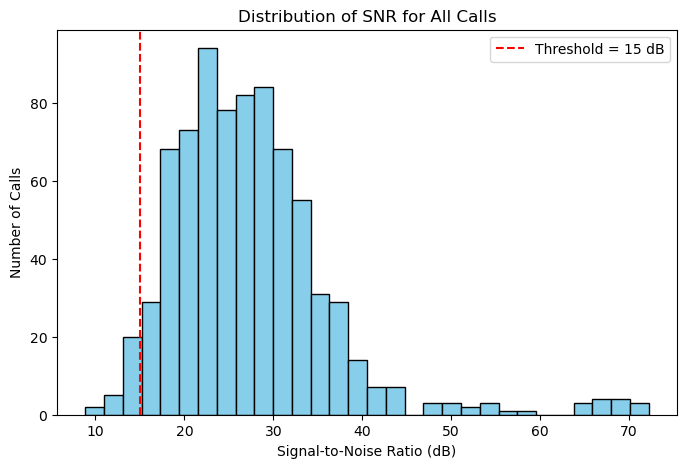

Min SNR: 8.85 dB
Mean SNR: 27.35 dB
Max SNR: 72.22 dB


In [8]:
SNR_THRESHOLD = 15  # Adjust after seeing histogram
plt.figure(figsize=(8, 5))
plt.hist(snr_df['SNR_dB'], bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Signal-to-Noise Ratio (dB)')
plt.ylabel('Number of Calls')
plt.title('Distribution of SNR for All Calls')
plt.axvline(SNR_THRESHOLD, color='red', linestyle='--', label=f'Threshold = {SNR_THRESHOLD} dB')
plt.legend()
plt.show()

print(f"Min SNR: {snr_df['SNR_dB'].min():.2f} dB")
print(f"Mean SNR: {snr_df['SNR_dB'].mean():.2f} dB")
print(f"Max SNR: {snr_df['SNR_dB'].max():.2f} dB")

## View Calls based on quality (snr)
- Creates a list of 'worst' calls to determine if they should be included. 

In [9]:
# Sort calls from lowest to highest SNR
low_snr_calls = snr_df.sort_values(by="SNR_dB", ascending=True)
low_snr_calls.to_csv("SNR_calls_sorted.csv", index=False)
print("Saved SNR_calls_sorted.csv")


Saved SNR_calls_sorted.csv


## Run SNR threshold
- Final definition of SNR threshold
- Only keeps audio files that are above that threshold

In [10]:
SNR_THRESHOLD = 15
kept_files = snr_df.loc[snr_df["SNR_dB"] >= SNR_THRESHOLD, "filename"].tolist()
print(f"Kept {len(kept_files)} files after SNR filtering.")

Kept 749 files after SNR filtering.


## Auto-Trimming Audio to remove silence at beginning and end
- can adjust settings below for more accurate trimming

In [11]:
def trim_for_classification(
    input_path,
    output_path,
    silence_db_below_avg=16, 
    min_silence_len_ms=150,
    keep_silence_ms=30,
    normalize=True):
    audio = AudioSegment.from_file(input_path)

    # choose a stable threshold
    # relative to file average, but do not go above a floor like -40 dBFS
    thresh = max(audio.dBFS - silence_db_below_avg, -40)

    # find all nonsilent spans
    spans = detect_nonsilent(audio,
                             min_silence_len=min_silence_len_ms,
                             silence_thresh=thresh)

    if not spans:
        # nothing detected, just export standardized audio
        audio.export(output_path, format="wav")
        return

    # keep only head to tail, do not collapse interior pauses
    start = max(spans[0][0] - keep_silence_ms, 0)
    end = min(spans[-1][1] + keep_silence_ms, len(audio))

    trimmed = audio[start:end]

    # optional: peak normalize for consistent amplitude, or skip if you do not want amplitude changes
    # target_peak_dbfs = -1.0
    # change = target_peak_dbfs - trimmed.max_dBFS
    # trimmed = trimmed.apply_gain(change)

    trimmed.export(output_path, format="wav")



In [12]:
TRIMMED_CALLS_DIR = "/data/calls_for_classification"
os.makedirs(TRIMMED_CALLS_DIR, exist_ok=True)
for fname in kept_files:
    in_path = os.path.join(ALL_CALLS_DIR, fname)
    out_path = os.path.join(TRIMMED_CALLS_DIR, fname)
    trim_for_classification(in_path, out_path)

print(f"Trimmed {len(kept_files)} calls for classification.")

KeyboardInterrupt: 

## Feature Extraction
- Extracts acoustic features from each call using Parselmouth and optionally librosa for spectral features.

In [ ]:
#Define pitch floor/ceiling. Based on manual measurements in PRAAT
PITCH_FLOOR = 50.0   # adjust for different lower bound
PITCH_CEILING = 2000.0   # or 2500, but keep this consistent with Praat


In [ ]:
def extract_features(filepath):
    snd = parselmouth.Sound(filepath)
       
    # use explicit pitch floor and ceiling
    pitch = snd.to_pitch(
        pitch_floor=PITCH_FLOOR,
        pitch_ceiling=PITCH_CEILING
    )

    formants = snd.to_formant_burg()
    intensity = snd.to_intensity()
    hnr = call(snd, "To Harmonicity (cc)", 0.01, 75, 0.1, 1.0)
    point_process = call(snd, "To PointProcess (periodic, cc)", 75, 5000)
    duration = snd.get_total_duration()

    try:
        mean_pitch = call(pitch, "Get mean", 0, 0, "Hertz")
    except:
        mean_pitch = np.nan
    try:
        stdev_pitch = call(pitch, "Get standard deviation", 0, 0, "Hertz")
    except:
        stdev_pitch = np.nan
    try:
        min_pitch = call(pitch, "Get minimum", 0, 0, "Hertz", "Parabolic")
    except:
        min_pitch = np.nan
    try:
        max_pitch = call(pitch, "Get maximum", 0, 0, "Hertz", "Parabolic")
    except:
        max_pitch = np.nan

    try:
        f1_mean = call(formants, "Get mean", 1, 0, 0, "Hertz")
        f2_mean = call(formants, "Get mean", 2, 0, 0, "Hertz")
        f3_mean = call(formants, "Get mean", 3, 0, 0, "Hertz")
    except:
        f1_mean = f2_mean = f3_mean = np.nan
    
    # --- formant dispersion (F2–F1 and F3–F2, then average) ---
    f12_hz = (f2_mean - f1_mean) if np.isfinite(f2_mean) and np.isfinite(f1_mean) else np.nan
    f23_hz = (f3_mean - f2_mean) if np.isfinite(f3_mean) and np.isfinite(f2_mean) else np.nan

    # if tracking glitches produce negative gaps, drop them
    if isinstance(f12_hz, (int, float)) and f12_hz < 0:
        f12_hz = np.nan
    if isinstance(f23_hz, (int, float)) and f23_hz < 0:
        f23_hz = np.nan

    formant_dispersion = np.nanmean([f12_hz, f23_hz])
    
    features = {
        "F0": mean_pitch,
        "sd_pitch": stdev_pitch,
        "min_pitch": min_pitch,
        "max_pitch": max_pitch,
        "pitch_instability": call(point_process, "Get jitter (local)", 0, 0, 0.0001, 0.02, 1.3),
        "amplitude_instability": call([snd, point_process], "Get shimmer (local)", 0, 0, 0.0001, 0.02, 1.3, 1.6),
        "F1": f1_mean,
        "F2": f2_mean,
        "call_intensity": call(intensity, "Get mean", 0, 0),
        "formant_dispersion": formant_dispersion,
        "harmonic-noise-ratio": call(hnr, "Get mean", 0, 0)
    }

    if INCLUDE_SPECTRAL_FEATURES: #only if toggled on at begginning of pipeline
        y, sr = librosa.load(filepath, sr=None)
        if NORMALIZE_AUDIO:
            y = normalize_audio_peak(y, target_dBFS=-1.0)
        features.update({
            "spectral_centroid": np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)),
            "spectral_bandwidth": np.mean(librosa.feature.spectral_bandwidth(y=y, sr=sr)),
            "spectral_rolloff": np.mean(librosa.feature.spectral_rolloff(y=y, sr=sr))
        })

    return features



### Process extraction
- Loops over the filtered list of calls and extracts features for each.

In [ ]:
TRIMMED_CALLS_DIR = "/data/calls_for_classification"

data = []
for file in kept_files:
    filepath = os.path.join(TRIMMED_CALLS_DIR, file)
    feats = extract_features(filepath)
    feats['filename'] = file
    data.append(feats)

features_df = pd.DataFrame(data)

## Merge Metadata
- Merges the extracted features with original dataset containing the correct individual IDs

In [ ]:
#gets rid of weird columns called 'unnamed'
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
features_df = features_df.loc[:, ~features_df.columns.str.startswith("Unnamed")]


In [ ]:
# list of columns coming from feature extractor
feature_cols = features_df.columns.tolist()

# keep only non feature columns from df (metadata)
meta_cols = [c for c in df.columns if c not in feature_cols or c == 'filename']

# merge metadata first, then features (cleaner column order)
df = pd.merge(df[meta_cols], features_df, on='filename', how='inner')

print("Merged dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

#THIS IS DATASET USED IN DOMINANCE ANALYSES. ALL individuals regardless of photocount
df.to_csv("fulldata.csv", index=False)
print("fulldata.csv")

In [3]:
#Lists how many calls each individual has. 
df = pd.read_csv("fulldata.csv")
df['individual'].value_counts().sort_values()


individual
CG       1
TAC      1
PLU      1
PAC      1
FD       2
CK       2
CHU      2
TIZ      3
ES       3
MAU      5
PIR      5
PIC      6
CER      6
PED      7
PER      7
MAN      8
YU      17
ANA     20
WD      21
BS      22
TRO     23
YW      32
WE      33
BD      34
MOZ     41
MC      47
AP      54
KN      54
CU      67
TOC     86
KRA    140
Name: count, dtype: int64

In [4]:
#MARK cutoff points. how many calls minimium for each ind. 
counts = df['individual'].value_counts()
valid_inds = counts[counts >= 17].index #can be 10 or 15

df = df[df['individual'].isin(valid_inds)].copy()

print("After filtering:", df['individual'].value_counts())
print("New shape:", df.shape)

After filtering: individual
KRA    140
TOC     86
CU      67
AP      54
KN      54
MC      47
MOZ     41
BD      34
WE      33
YW      32
TRO     23
BS      22
WD      21
ANA     20
YU      17
Name: count, dtype: int64
New shape: (691, 24)


In [5]:
# Creates dataset with individuals with a min of 10 calls 
# clean unnamed columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

# drop fully empty columns
df = df.dropna(axis=1, how='all')

# drop Notes column if present
if 'Notes' in df.columns:
    df = df.drop(columns=['Notes'])

df.to_csv("individual_analyses.csv", index=False)
print("Saved individual_analyses.csv")


Saved individual_analyses.csv


In [2]:
df = pd.read_csv("individual_analyses.csv")

print("Shape:", df.shape)
print("Individuals per site:")
print(df.groupby("Site")["individual"].nunique())

Shape: (691, 24)
Individuals per site:
Site
SSR    13
TAB     2
Name: individual, dtype: int64


In [3]:
import pandas as pd
import numpy as np

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score

df = pd.read_csv("individual_analyses.csv")

# Standardize column names just in case
df.columns = df.columns.astype(str).str.strip()

# Ensure these exist and are strings
for c in ["individual", "Site"]:
    df[c] = df[c].astype(str).str.strip()

# 1) Select ONLY numeric feature columns
# This automatically drops columns like group = "AD"
numeric_df = df.select_dtypes(include=[np.number])

# If you know there are numeric metadata columns you do NOT want, drop them here
# Example: if you have a numeric "age_code" or "rating" that is not an acoustic feature
drop_numeric_metadata = [c for c in ["rating"] if c in numeric_df.columns]
numeric_df = numeric_df.drop(columns=drop_numeric_metadata, errors="ignore")

X = numeric_df.values
y = df["Site"].values
individuals = df["individual"].values

print("Numeric feature columns used:", numeric_df.columns.tolist())
print("X shape:", X.shape)


Numeric feature columns used: ['Sequence call length', 'Sequence position', 'call_length', 'F0', 'sd_pitch', 'min_pitch', 'max_pitch', 'pitch_instability', 'amplitude_instability', 'F1', 'F2', 'call_intensity', 'formant_dispersion', 'harmonic-noise-ratio']
X shape: (691, 14)


In [4]:
unique_inds = np.unique(individuals)

y_true = []
y_pred = []

for ind in unique_inds:
    train_idx = individuals != ind
    test_idx = individuals == ind

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    clf = LinearDiscriminantAnalysis()
    clf.fit(X_train, y_train)

    preds = clf.predict(X_test)

    y_true.extend(y_test)
    y_pred.extend(preds)

balanced_acc = balanced_accuracy_score(y_true, y_pred)

print("LOIO Balanced Accuracy (Site):", balanced_acc)


LOIO Balanced Accuracy (Site): 0.47368421052631576


### Optional: Test models with minimum 5, 10, 15 calls per individuals

In [ ]:
#comparing models if using minimum 5, 10, 15 calls per individual

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd

# thresholds to compare
min_calls_list = [5, 10, 15]

rf_summaries = []
pic_tables = {}
rf_importances = {}

group_col = "individual"  # change if you later want to use 'Rank' etc.

for min_calls in min_calls_list:
    print("=" * 70)
    print(f"Minimum calls per {group_col}: {min_calls}")
    
    # subset individuals by minimum call count
    counts = df[group_col].value_counts()
    keep_inds = counts[counts >= min_calls].index
    df_sub = df[df[group_col].isin(keep_inds)].copy()
    
    n_inds = len(keep_inds)
    n_calls = len(df_sub)
    print(f"Kept {n_inds} {group_col}s and {n_calls} calls")
    
    # numeric features for modeling
    X = df_sub.select_dtypes(include=[np.number])
    y = df_sub[group_col]
    
    # drop any rows with NaNs in features
    mask = ~X.isna().any(axis=1)
    X = X[mask]
    y = y[mask]
    
    print(f"After dropping NaN rows: {X.shape[0]} calls, {X.shape[1]} numeric features")
    
    # standardize
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Random Forest with LOOCV accuracy
    rf = RandomForestClassifier(
        n_estimators=500,
        class_weight="balanced",
        random_state=42
    )
    
    loo = LeaveOneOut()
    rf_acc_scores = cross_val_score(
        rf,
        X_scaled, y,
        cv=loo,
        scoring="accuracy"
    )
    
    mean_acc = rf_acc_scores.mean()
    sd_acc = rf_acc_scores.std()
    print(f"LOOCV RF accuracy: {mean_acc:.3f} ± {sd_acc:.3f}")
    
    # fit RF on all data for feature importances
    rf.fit(X_scaled, y)
    imp_series = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
    rf_importances[min_calls] = imp_series
    
    print("\nTop 10 RF feature importances:")
    print(imp_series.head(10))
    
    # store RF summary
    rf_summaries.append({
        "min_calls": min_calls,
        "n_individuals": n_inds,
        "n_calls": n_calls,
        "rf_loocv_acc_mean": mean_acc,
        "rf_loocv_acc_sd": sd_acc
    })
    
    # PIC calculation per feature
    # based on CV_between and CV_within across individuals
    feat_cols = X.columns
    pic_rows = []
    
    for feat in feat_cols:
        vals = df_sub[[group_col, feat]].dropna()
        if vals.empty:
            continue
        
        # global mean for scaling CVs
        global_mean = vals[feat].mean()
        if global_mean == 0 or not np.isfinite(global_mean):
            continue
        
        # between individual: SD of per individual means divided by global mean
        group_means = vals.groupby(group_col)[feat].mean()
        cv_between = group_means.std(ddof=1) / global_mean
        
        # within individual: mean of within individual SDs divided by global mean
        within_sds = vals.groupby(group_col)[feat].std(ddof=1)
        cv_within = np.nanmean(within_sds) / global_mean
        
        pic = cv_between / cv_within if cv_within not in [0, np.nan] else np.nan
        
        pic_rows.append({
            "Feature": feat,
            "CV_between": cv_between,
            "CV_within": cv_within,
            "PIC": pic
        })
    
    pic_df = pd.DataFrame(pic_rows).sort_values("PIC", ascending=False)
    pic_tables[min_calls] = pic_df
    
    print("\nTop 10 PIC features:")
    print(pic_df.head(10)[["Feature", "CV_between", "CV_within", "PIC"]])

print("=" * 70)
print("\nSummary across thresholds:")
rf_summary_df = pd.DataFrame(rf_summaries)
display(rf_summary_df)


## Prepare Dataset for Classification
- Checks data for NAs before filtering
- Standardizes the feature set
- Prepares data for final Analyses

In [7]:
# Check numeric columns and NaNs before filtering
X = df.select_dtypes(include=[np.number])

print("Shape of numeric features BEFORE filtering:", X.shape)
print("Number of rows with ALL NaNs:", (X.isna().all(axis=1)).sum())
print("Number of rows with ANY NaNs:", (X.isna().any(axis=1)).sum())
print("\nNaN count per column:")
print(X.isna().sum())

nan_details = df[df.isna().any(axis=1)][["filename"] + X.columns.tolist()]
nan_details

Shape of numeric features BEFORE filtering: (691, 15)
Number of rows with ALL NaNs: 0
Number of rows with ANY NaNs: 0

NaN count per column:
rating                   0
Sequence call length     0
Sequence position        0
call_length              0
F0                       0
sd_pitch                 0
min_pitch                0
max_pitch                0
pitch_instability        0
amplitude_instability    0
F1                       0
F2                       0
call_intensity           0
formant_dispersion       0
harmonic-noise-ratio     0
dtype: int64


,filename,rating,Sequence call length,Sequence position,call_length,F0,sd_pitch,min_pitch,max_pitch,pitch_instability,amplitude_instability,F1,F2,call_intensity,formant_dispersion,harmonic-noise-ratio
0,2025_05_02_ANA_BC_vla.wav,2,1,1,0.750,1010.245832,226.446176,459.206414,1169.203747,0.075189,0.195574,1013.254142,1749.706792,64.566417,925.477976,5.992337
1,2025_05_02_ANA_BC_vlc1.wav,2,1,1,0.849,1108.382944,106.020623,978.561975,1385.167445,0.081791,0.211880,1083.699818,1625.619553,63.742868,805.551100,6.228211
2,2025_05_02_ANA_BC_vlc2.wav,2,2,1,0.601,1129.722018,31.078487,1036.973422,1191.818910,0.085418,0.233109,1084.929301,1517.035523,67.410574,830.738947,3.597055
3,2025_05_02_ANA_BC_vlc3.wav,2,2,2,0.648,1086.675386,20.728555,1046.310451,1135.379605,0.083186,0.211069,1068.812773,1598.184957,68.389359,728.571325,5.198761
4,2025_05_02_ANA_BC_vlc4.wav,2,1,1,0.803,1113.377276,31.761517,1060.795273,1225.694416,0.073477,0.214863,1095.139401,1560.863904,79.060079,818.597914,6.935727
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
675,2025_03_26_YW_SS_vlr8.wav,1,1,1,0.546,1124.124651,23.177124,1074.822368,1173.843097,0.079396,0.233885,1108.447885,1694.462368,69.380904,664.189204,2.925934
683,2025_04_17_YW_SS_LOSTADLIB_vli15.wav,1,2,2,0.881,1210.082575,38.233672,1120.254128,1302.127830,0.083109,0.231076,1166.151566,1736.213214,75.229080,753.999597,4.123833
685,2025_04_17_YW_SS_LOSTADLIB_vli17.wav,1,2,2,1.029,1136.292546,25.616111,1065.306409,1182.711795,0.077965,0.215118,1130.617952,1732.291388,66.150546,767.925150,4.263713
686,2025_04_17_YW_SS_LOSTADLIB_vli19.wav,1,2,2,0.748,1175.358549,33.503713,1068.962293,1222.226883,0.064604,0.213681,1160.890348,1780.862214,67.601039,789.368684,6.706909


In [8]:
#Standardize features
# Prepare features and labels
X_all = df.select_dtypes(include=[np.number])
y_all = df['individual']

# Mask of rows with NO NaNs
mask = ~X_all.isna().any(axis=1)

# Count how many rows dropped
n_total = len(df)
n_kept = mask.sum()
n_dropped = n_total - n_kept

print(f"Total calls: {n_total}")
print(f"Calls kept: {n_kept}")
print(f"Calls dropped due to missing feature(s): {n_dropped}")

# Now apply the mask
X = X_all[mask]
y = y_all[mask]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



Total calls: 691
Calls kept: 691
Calls dropped due to missing feature(s): 0


### Reduce irrelevant features before final analysis
- ONLY removed Rating & sequence position. models work better with all features. 

In [9]:
# ==== toggle ====
RUN_FEATURE_DROP = True   # set to False to skip this cell

if RUN_FEATURE_DROP:
    # config
    DROP_FEATURES = [
        "rating", "Sequence position"]

    # drop only what exists
    cols_to_drop = [c for c in DROP_FEATURES if c in X.columns]
    if cols_to_drop:
        X = X.drop(columns=cols_to_drop)
        print("Dropped:", cols_to_drop)
    else:
        print("No matching features to drop")

    # keep df and X row aligned
    # if you already ensured alignment earlier, this is harmless
    df = df.loc[X.index].reset_index(drop=True)
    X = X.reset_index(drop=True)

    # ensure only numeric columns go to the scaler
    numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    if len(numeric_cols) != X.shape[1]:
        removed = [c for c in X.columns if c not in numeric_cols]
        print("Non numeric columns removed before scaling:", removed)
        X = X[numeric_cols]

    # guardrails
    assert X.shape[0] == df.shape[0], "df and X are not row aligned"
    assert X.shape[1] > 0, "No features left in X after drop"

    # scale
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(
        scaler.fit_transform(X),
        columns=X.columns,
        index=X.index
    )
    print("X_scaled rebuilt with", X_scaled.shape[1], "features")
else:
    print("Feature drop cell skipped")


Dropped: ['rating', 'Sequence position']
X_scaled rebuilt with 13 features


## Calculate Potential for Identity Coding (PIC) Values

In [10]:
# restrict PIC calculation to a specific set of acoustic features
pic_features = [
        "F0",
    "sd_pitch",
    "min_pitch",
    "max_pitch",
    "pitch_instability",
    "amplitude_instability",
    "F1",
    "F2",
    "call_intensity",
    "formant_dispersion",
    "harmonic-noise-ratio",
    "call_length"
]

# keep only features that are actually present in df
pic_features = [f for f in pic_features if f in df.columns]

pic_results = []

for col in pic_features:
    means_per_ind = df.groupby("individual")[col].mean()

    cv_between = np.std(means_per_ind, ddof=1) / np.mean(means_per_ind)

    within_cvs = []
    for ind in df["individual"].unique():
        vals = df.loc[df["individual"] == ind, col].dropna()
        if len(vals) > 1:
            within_cvs.append(np.std(vals, ddof=1) / np.mean(vals))

    cv_within = np.mean(within_cvs) if len(within_cvs) > 0 else np.nan
    pic = cv_between / cv_within if (cv_within is not None and not np.isnan(cv_within) and cv_within != 0) else np.nan

    pic_results.append((col, cv_between, cv_within, pic))

pic_df = pd.DataFrame(pic_results, columns=["Feature", "CV_between", "CV_within", "PIC"])
pic_df["PIC"] = pic_df["PIC"].round(3)
pic_df = pic_df.sort_values("PIC", ascending=False)

print("\nPIC Index Results (PIC > 1 suggests strong identity cue):")
print(pic_df)



PIC Index Results (PIC > 1 suggests strong identity cue):
                  Feature  CV_between  CV_within    PIC
6                      F1    0.048182   0.030281  1.591
0                      F0    0.053321   0.038475  1.386
11            call_length    0.177691   0.155618  1.142
9      formant_dispersion    0.076592   0.083956  0.912
10   harmonic-noise-ratio    0.259796   0.318188  0.816
4       pitch_instability    0.109793   0.135057  0.813
3               max_pitch    0.052497   0.085072  0.617
8          call_intensity    0.046233   0.075430  0.613
7                      F2    0.031286   0.051468  0.608
5   amplitude_instability    0.050410   0.085413  0.590
2               min_pitch    0.065143   0.142231  0.458
1                sd_pitch    0.374085   0.851844  0.439


## Random Forest Classification of Individual Identity

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

ID_COL = "individual"

rf_features = [
    "F0",
    "sd_pitch",
    "min_pitch",
    "max_pitch",
    "pitch_instability",
    "amplitude_instability",
    "F1",
    "F2",
    "formant_dispersion",
    "harmonic-noise-ratio",
    "call_length"
]

# Build X and y explicitly
missing = [f for f in rf_features if f not in df.columns]
if missing:
    raise ValueError(f"Missing RF features in df: {missing}")

X = df[rf_features].apply(pd.to_numeric, errors="coerce")
y = df[ID_COL].astype(str)

# Drop rows with any non-finite feature values
mask = np.isfinite(X.values).all(axis=1)
X2 = X.loc[mask].copy()
y2 = y.loc[mask].values

labels = np.unique(y2)

rf = RandomForestClassifier(
    n_estimators=500,
    max_features=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

loo = LeaveOneOut()

# LOOCV predictions (one call held out per fold)
y_hat = cross_val_predict(rf, X2, y2, cv=loo, n_jobs=-1)

# Primary metric
bac = balanced_accuracy_score(y2, y_hat)
print(f"RF LOOCV balanced accuracy: {bac:.3f}")

print("\nCross validated classification report:")
print(classification_report(y2, y_hat, labels=labels, zero_division=0))

cm = confusion_matrix(y2, y_hat, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
cm_df.to_csv("rf_loocv_results.csv", index=True)
print("Saved: rf_loocv_results.csv")


RF LOOCV balanced accuracy: 0.544

Cross validated classification report:
              precision    recall  f1-score   support

         ANA       0.37      0.35      0.36        20
          AP       0.74      0.65      0.69        54
          BD       0.38      0.47      0.42        34
          BS       0.22      0.09      0.13        22
          CU       0.76      0.81      0.78        67
          KN       0.72      0.61      0.66        54
         KRA       0.95      0.97      0.96       140
          MC       0.42      0.40      0.41        47
         MOZ       0.76      0.85      0.80        41
         TOC       0.63      0.84      0.72        86
         TRO       0.52      0.61      0.56        23
          WD       0.56      0.43      0.49        21
          WE       0.40      0.48      0.44        33
          YU       0.64      0.53      0.58        17
          YW       0.17      0.06      0.09        32

    accuracy                           0.66       691
   mac

Saved: rf_identity_permutation_importance.csv
                  Feature  Importance_mean  Importance_sd  \
10            call_length         0.331056       0.016468   
6                      F1         0.108303       0.009959   
0                      F0         0.099776       0.011173   
8      formant_dispersion         0.064713       0.009570   
7                      F2         0.029672       0.005425   
4       pitch_instability         0.023035       0.005846   
5   amplitude_instability         0.020372       0.005514   
1                sd_pitch         0.007836       0.003665   
2               min_pitch         0.006334       0.002730   
9    harmonic-noise-ratio         0.005655       0.002843   
3               max_pitch         0.002287       0.002172   

              Feature_label  
10            Call duration  
6                        F1  
0                   Mean F0  
8        Formant dispersion  
7                        F2  
4            F0 instability  
5     Ampli

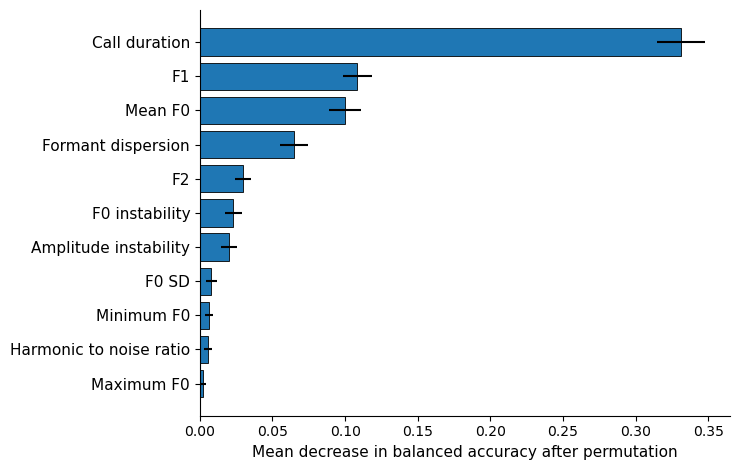

In [13]:
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score, make_scorer

# Fit RF on the full dataset used for LOOCV evaluation
rf.fit(X2, y2)

scorer = make_scorer(balanced_accuracy_score)

perm = permutation_importance(
    rf,
    X2,
    y2,
    n_repeats=50,
    scoring=scorer,
    random_state=42,
    n_jobs=-1
)

imp_df = pd.DataFrame({
    "Feature": X2.columns,
    "Importance_mean": perm.importances_mean,
    "Importance_sd": perm.importances_std
}).sort_values("Importance_mean", ascending=False)

# Rename features for publication
feature_labels = {
    "call_length": "Call duration",
    "F0": "Mean F0",
    "F1": "F1",
    "F2": "F2",
    "formant_dispersion": "Formant dispersion",
    "pitch_instability": "F0 instability",
    "sd_pitch": "F0 SD",
    "min_pitch": "Minimum F0",
    "max_pitch": "Maximum F0",
    "call_intensity": "Call intensity",
    "amplitude_instability": "Amplitude instability",
    "harmonic-noise-ratio": "Harmonic to noise ratio"
}

imp_df["Feature_label"] = imp_df["Feature"].map(feature_labels).fillna(imp_df["Feature"])

# Save numeric results
imp_df.to_csv("rf_identity_permutation_importance.csv", index=False)
print("Saved: rf_identity_permutation_importance.csv")
print(imp_df)

# ---- plot ----
top_n = 12
plot_df = imp_df.head(top_n).iloc[::-1]  # reverse for horizontal bars

fig, ax = plt.subplots(figsize=(7.5, 4.8))

ax.barh(
    plot_df["Feature_label"],
    plot_df["Importance_mean"],
    xerr=plot_df["Importance_sd"],
    height=0.8,
    edgecolor="black",
    linewidth=0.6
)

# Clean up appearance
ax.set_xlabel("Mean decrease in balanced accuracy after permutation", fontsize=11)
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=11)
ax.tick_params(axis="x", labelsize=10)

# Remove top and right spines for a cleaner journal style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Keep background white
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.savefig("rf_identity_feature_importance.png", dpi=600, bbox_inches="tight")
plt.show()
